# Greining á fjárlögum – félags- og húsnæðismál

**Spurning:** Hvernig þróast útgjöld ríkisins til félags- og húsnæðismála 2024–2028, og hvar liggja stærstu breytingarnar?

**Gögn:** Talnagögn úr fjárlagafrumvarpi 2026 (stjornarradid.is). Upphæðir í **milljónum króna**, á **nafnvirði**.

**Helstu niðurstöður:**
- Félags- og húsnæðismál (málefnasvið 27–32) eru um **25,6%** af heildarútgjöldum ríkisins, og hlutdeildin er nánast óbreytt 2024–2028.
- Mesti vöxturinn 2024→2026 er í **örorku (+21,5%)**. Stór hluti hans er þó **endurflokkun** milli málaflokka vegna nýs örorkulífeyriskerfis, ekki eingöngu raunaukning.
- **Húsnæðismál lækka um 18,7%** 2024→2026, og samkvæmt áætlun halda þau áfram að lækka til 2028.
- Örorka og málefni aldraðra eru nær eingöngu **tilfærslur til fólks**. Þar ráða bótareglur og fjöldi bótaþega útgjöldunum, ekki rekstur.

## 1. Uppsetning

Við flytjum inn tvo pakka:
- **pandas** – vinnur með töflur (eins og Excel, en í kóða). Venja er að kalla það `pd`.
- **matplotlib** – teiknar gröf. Venja er að kalla það `plt`.

`pd.set_option(...)` stillir hvernig tölur birtast: með þúsundaskilum og einum aukastaf, svo auðveldara sé að lesa þær.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)

## 2. Lesa gögnin

CSV-skráin er á íslensku sniði, svo við þurfum að segja pandas þrennt:
- `sep=";"` – dálkar eru aðskildir með **semíkommu** (ekki kommu, því komman er notuð sem tugabrot).
- `decimal=","` – **komma** er tugabrotsmerki (9968,4 en ekki 9968.4).
- `encoding="utf-8-sig"` – stafatöflan, svo að þ, ð, æ, ö komi rétt út. `-sig` sleppir ósýnilegu merki (BOM) í byrjun skrárinnar.

`glob("*.csv")` finnur hvaða CSV-skrá sem er í `gogn`-möppunni, svo nafnið skiptir ekki máli.

In [2]:
csv_skra = next(Path("gogn").glob("*.csv"))
df = pd.read_csv(csv_skra, sep=";", decimal=",", encoding="utf-8-sig")
print(csv_skra)

gogn/fjarlog_2026.csv


## 3. Kynnast gögnunum

Fyrsta regla greinanda: **skoðaðu gögnin áður en þú reiknar.** Hversu margar línur? Hvaða dálkar? Hvernig líta gildin út?

- `df.shape` – (fjöldi lína, fjöldi dálka)
- `df.head()` – fyrstu 5 línurnar
- `df.dtypes` – tegund hvers dálks (tala eða texti). Ef `Upphæð` væri texti hefði `decimal=","` klikkað.

In [3]:
print(df.shape)
df.head()

(29478, 10)


,Ár,Afurð,FlokkunNy,Málefnasvið,Málaflokkur,Ráðuneyti,Liður,Viðfang,TegundNota,Upphæð
0,2024,Ríkisreikningur,NaN,31 Húsnæðis- og skipulagsmál,31.10 Húsnæðismál,07 Félags- og húsnæðismálaráðuneyti,07-275 Húsnæðisbætur,110 Húsnæðisbætur,Gjöld,"9,968.4"
1,2024,Ríkisreikningur,NaN,31 Húsnæðis- og skipulagsmál,31.10 Húsnæðismál,07 Félags- og húsnæðismálaráðuneyti,07-275 Húsnæðisbætur,110 Húsnæðisbætur,Tekjur,0.0
2,2024,Ríkisreikningur,NaN,31 Húsnæðis- og skipulagsmál,31.10 Húsnæðismál,07 Félags- og húsnæðismálaráðuneyti,07-275 Húsnæðisbætur,110 Húsnæðisbætur,Fjárhæð,"9,968.4"
3,2024,Ríkisreikningur,NaN,31 Húsnæðis- og skipulagsmál,31.10 Húsnæðismál,07 Félags- og húsnæðismálaráðuneyti,07-275 Húsnæðisbætur,110 Húsnæðisbætur,Greiðsla,"9,968.4"
4,2024,Ríkisreikningur,NaN,31 Húsnæðis- og skipulagsmál,31.10 Húsnæðismál,07 Félags- og húsnæðismálaráðuneyti,07-275 Húsnæðisbætur,110 Húsnæðisbætur,Rekstrarframlög,0.0


In [4]:
df.dtypes

Ár               int64
Afurð              str
FlokkunNy          str
Málefnasvið        str
Málaflokkur        str
Ráðuneyti          str
Liður              str
Viðfang            str
TegundNota         str
Upphæð         float64
dtype: object

`value_counts()` telur hversu oft hvert gildi kemur fyrir. Hér sjáum við mikilvægt atriði: **hvert ár er ólík tegund af tölu.**

| Ár | Afurð | Merking |
|---|---|---|
| 2024 | Ríkisreikningur | Raunveruleg útgjöld |
| 2025 | Fjárlög | Samþykktar fjárheimildir |
| 2026 | Frumvarp | Tillaga ríkisstjórnar |
| 2027–28 | Áætlun | Spá |

Þegar við berum saman 2024 og 2026 erum við því að bera saman *raun* og *tillögu*. Það þarf að segja frá því í niðurstöðum.

In [5]:
df.groupby(["Ár", "Afurð"]).size()

Ár    Afurð          
2024  Ríkisreikningur    7640
2025  Fjárlög            7400
2026  Frumvarp           7310
2027  Áætlun             3564
2028  Áætlun             3564
dtype: int64

Dálkurinn `TegundNota` segir hvaða mæling er í línunni. **Sama upphæð getur komið fyrir í mörgum línum** (t.d. bæði sem `Gjöld` og `Heildarútgjöld`). Ef við leggjum allt saman tvítelst því allt.

Við notum **`Heildarútgjöld`**, sem er ein lína á hvert viðfang og ár og er til fyrir öll árin.

In [6]:
df["TegundNota"].value_counts()

TegundNota
Fjárhæð                 4017
Greiðsla                4017
Heildarútgjöld          4017
Rekstrartekjur          4017
Gjöld                   2235
Tekjur                  2235
Rekstrarframlög         2235
Rekstrartilfærslur      2235
Fjármagnstilfærslur     2235
Fjárfestingarframlög    2235
Name: count, dtype: int64

## 4. Sía gögnin

Við búum til tvær töflur:
- `heild` – öll heildarútgjöld ríkisins (til að reikna hlutdeild síðar).
- `fel` – bara málefnasvið **27–32** (félags- og húsnæðismál).

`.str[:2]` tekur fyrstu tvo stafina úr textanum („31 Húsnæðis- og…“ → „31“) og `.isin([...])` athugar hvort gildið sé í listanum.

**Af hverju síum við eftir málefnasviði en ekki ráðuneyti?** Félags- og húsnæðismálaráðuneytið varð til í mars 2025. Í fjárlögum 2025 voru húsnæðismál enn skráð á innviðaráðuneytið, svo ef síað væri eftir ráðuneyti hyrfi árið 2025 úr húsnæðismálum.

In [7]:
heild = df[df["TegundNota"] == "Heildarútgjöld"]

MALEFNASVID = ["27", "28", "29", "30", "31", "32"]
fel = heild[heild["Málefnasvið"].str[:2].isin(MALEFNASVID)]

print(len(heild), "línur alls,", len(fel), "línur í félags- og húsnæðismálum")

4017 línur alls, 678 línur í félags- og húsnæðismálum


## 5. Útgjöld eftir málefnasviðum og árum

`pivot_table` er eins og pivot-tafla í Excel:
- `index` – það sem fer í línur (málefnasvið)
- `columns` – það sem fer í dálka (ár)
- `values` + `aggfunc="sum"` – hvað er lagt saman

In [8]:
eftir_svidum = fel.pivot_table(
    index="Málefnasvið", columns="Ár", values="Upphæð", aggfunc="sum"
)
eftir_svidum

Ár,2024,2025,2026,2027,2028
Málefnasvið,,,,,
27 Örorka og málefni fatlaðs fólks,"109,164.0","112,523.2","132,621.8","133,437.1","134,465.7"
28 Málefni aldraðra,"109,594.2","121,569.9","127,566.1","132,158.1","138,858.1"
29 Fjölskyldumál,"70,431.5","75,711.0","82,574.7","81,061.0","82,013.0"
30 Vinnumarkaður og atvinnuleysi,"46,851.4","43,863.0","46,210.5","42,809.1","43,664.7"
31 Húsnæðis- og skipulagsmál,"31,840.2","27,851.1","25,901.9","27,067.7","21,200.2"
32 Lýðheilsa og stjórnsýsla velferðarmála,"13,355.5","12,521.0","12,973.8","12,847.3","12,775.5"


## 6. Vöxtur

Hlutfallsleg breyting = (nýtt / gamalt − 1) × 100.

Í pandas er hægt að reikna á heilum dálkum í einu, án lykkju. `eftir_svidum[2026] / eftir_svidum[2024]` deilir hverri línu fyrir sig.

In [9]:
voxtur = pd.DataFrame({
    "2024 (raun)": eftir_svidum[2024],
    "2026 (frumvarp)": eftir_svidum[2026],
    "breyting_mkr": eftir_svidum[2026] - eftir_svidum[2024],
    "breyting_%": (eftir_svidum[2026] / eftir_svidum[2024] - 1) * 100,
})
voxtur.sort_values("breyting_%", ascending=False)

,2024 (raun),2026 (frumvarp),breyting_mkr,breyting_%
Málefnasvið,,,,
27 Örorka og málefni fatlaðs fólks,"109,164.0","132,621.8","23,457.8",21.5
29 Fjölskyldumál,"70,431.5","82,574.7","12,143.2",17.2
28 Málefni aldraðra,"109,594.2","127,566.1","17,971.9",16.4
30 Vinnumarkaður og atvinnuleysi,"46,851.4","46,210.5",-640.9,-1.4
32 Lýðheilsa og stjórnsýsla velferðarmála,"13,355.5","12,973.8",-381.7,-2.9
31 Húsnæðis- og skipulagsmál,"31,840.2","25,901.9","-5,938.3",-18.7


## 7. Hlutdeild af heildarútgjöldum ríkisins

Hækka útgjöldin til félagsmála *meira* en önnur útgjöld ríkisins, eða bara í takt við þau? Til að svara því reiknum við hlutfall af heild.

`groupby("Ár")["Upphæð"].sum()` leggur saman upphæðir fyrir hvert ár. Þegar við deilum tveimur slíkum röðum parar pandas árin saman sjálfkrafa.

In [10]:
fel_alls = fel.groupby("Ár")["Upphæð"].sum()
rikid_alls = heild.groupby("Ár")["Upphæð"].sum()

hlutdeild = pd.DataFrame({
    "félags- og húsnæðismál": fel_alls,
    "ríkið alls": rikid_alls,
    "hlutdeild_%": fel_alls / rikid_alls * 100,
})
hlutdeild

,félags- og húsnæðismál,ríkið alls,hlutdeild_%
Ár,,,
2024,"381,236.8","1,491,095.1",25.6
2025,"394,039.2","1,545,639.5",25.5
2026,"427,848.8","1,672,186.3",25.6
2027,"429,380.3","1,670,061.2",25.7
2028,"432,977.2","1,700,003.4",25.5


**Túlkun:** Hlutdeildin er nánast óbreytt (um 25,6%). Félagsmálin stækka því í takt við ríkisútgjöldin í heild, ekki umfram þau.

## 8. Graf: þróun eftir málefnasviðum

`.T` snýr töflunni (*transpose*), þannig að árin verða línur og málefnasviðin dálkar. Þá teiknar `.plot()` eina línu fyrir hvert málefnasvið.

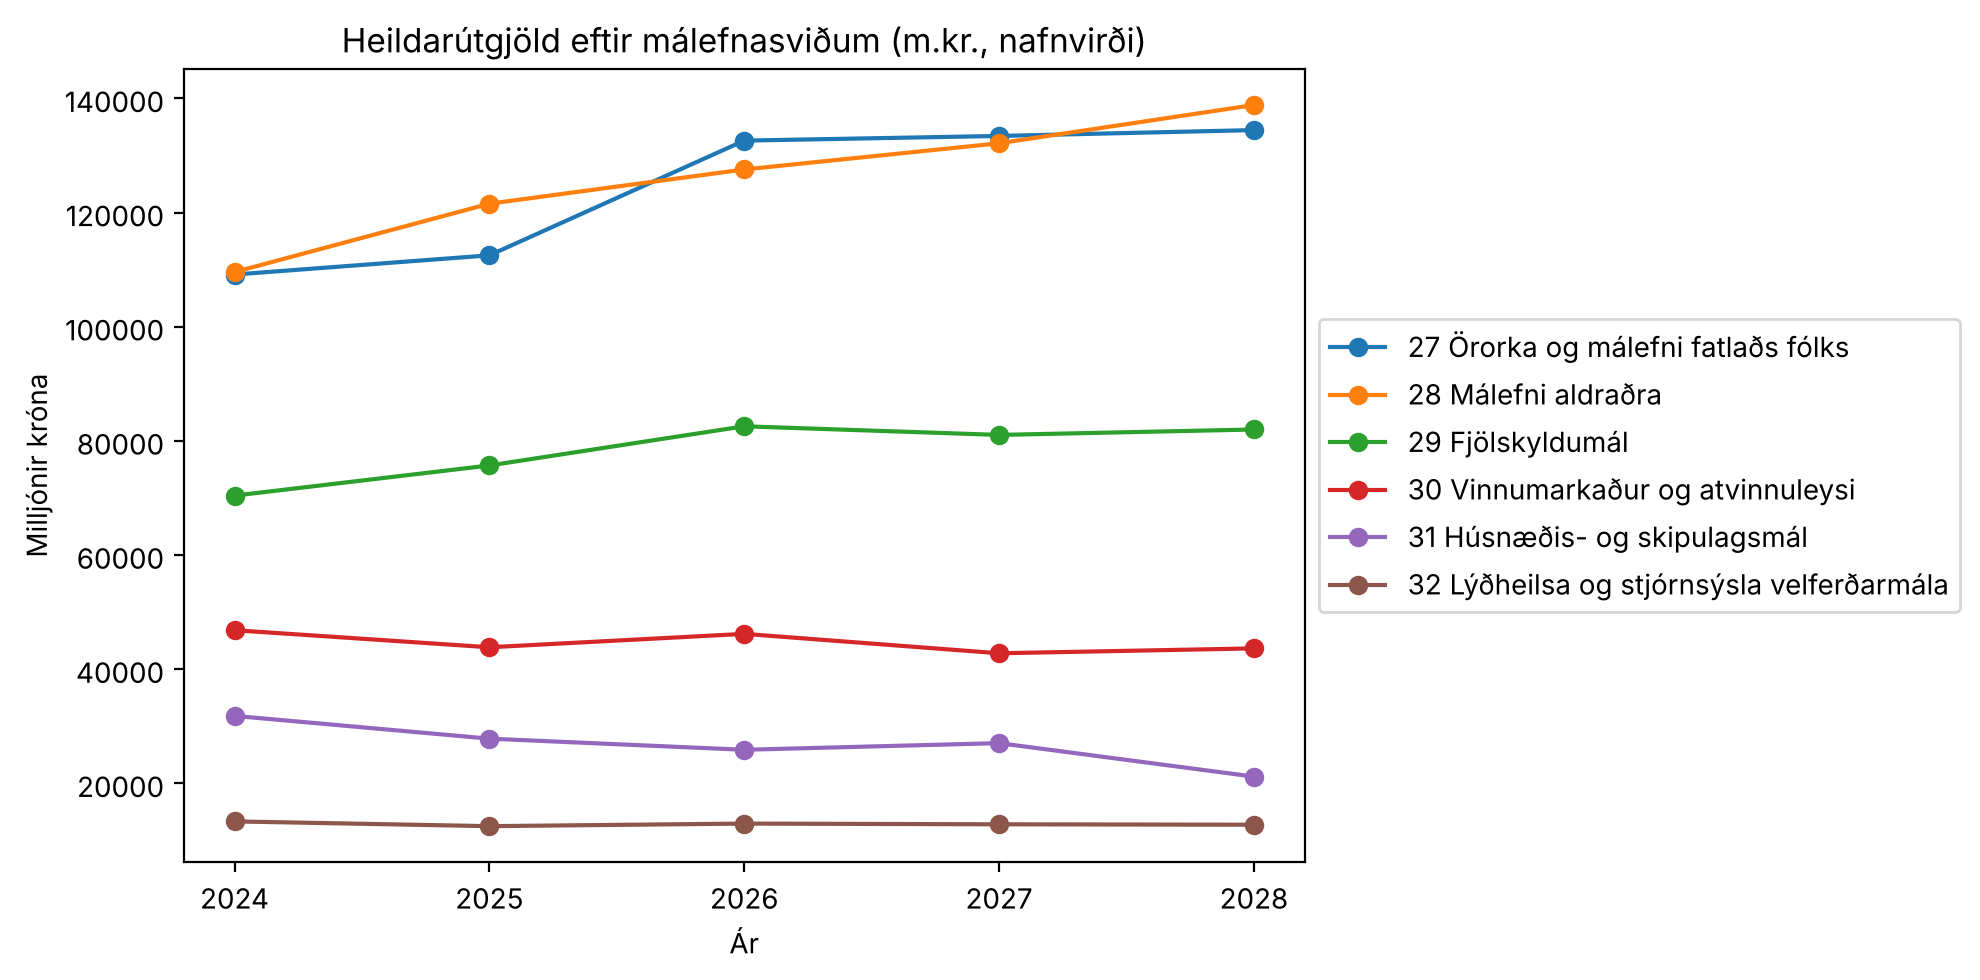

In [11]:
ax = eftir_svidum.T.plot(marker="o", figsize=(10, 5))
ax.set_title("Heildarútgjöld eftir málefnasviðum (m.kr., nafnvirði)")
ax.set_ylabel("Milljónir króna")
ax.set_xticks(eftir_svidum.columns)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 9. Ein dýpra: hvaða málaflokkar breytast mest?

Málefnasvið skiptast í **málaflokka** (t.d. 27.10, 27.20). Við förum einu stigi neðar til að sjá *hvar* breytingarnar liggja.

`fillna(0)` setur 0 þar sem málaflokkur er ekki til tiltekið ár (annars kæmi `NaN` og frádrátturinn klikkaði).

In [12]:
malaflokkar = fel.pivot_table(
    index="Málaflokkur", columns="Ár", values="Upphæð", aggfunc="sum"
).fillna(0)

malaflokkar["breyting_24_26"] = malaflokkar[2026] - malaflokkar[2024]
malaflokkar.sort_values("breyting_24_26")[[2024, 2025, 2026, "breyting_24_26"]]

Ár,2024,2025,2026,breyting_24_26
Málaflokkur,,,,
"27.20 Bætur skv. lögum um félagslega aðstoð, örorka","40,046.4","39,126.2","17,391.2","-22,655.2"
27.50 Jöfnun á örorkubyrði almennra lífeyrissjóða,"6,896.0","4,507.4",0.0,"-6,896.0"
31.10 Húsnæðismál,"30,915.8","27,036.8","25,070.4","-5,845.4"
27.30 Málefni fatlaðs fólks,"1,734.4",135.8,83.2,"-1,651.2"
"32.10 Lýðheilsa, forvarnir og eftirlit","4,825.2","3,442.8","3,465.6","-1,359.6"
30.10 Vinnumál og atvinnuleysi,"45,161.5","41,988.6","44,276.7",-884.8
31.20 Skipulagsmál,924.4,814.3,831.5,-92.9
32.20 Jafnréttismál,334.1,394.7,398.2,64.1
29.50 Bætur til eftirlifenda,499.3,590.5,615.3,116.0


**Taktu eftir:** 27.10 (örorkulífeyrir) hækkar um ~54 ma.kr. á sama tíma og 27.20 (félagsleg aðstoð, örorka) lækkar um ~23 ma.kr. Þetta lítur út fyrir að vera **endurflokkun** vegna nýs örorkulífeyriskerfis haustið 2025, ekki eingöngu raunaukning.

Þetta er dæmigerð gildra í gagnagreiningu: stór breyting í einum flokki getur verið tilfærsla úr öðrum. **Skoðaðu alltaf heildina samhliða.**

## 10. Í hvað fara peningarnir?

Útgjöldum er skipt í tegundir:
- **Rekstrarframlög** – rekstur stofnana (laun, húsnæði o.fl.)
- **Rekstrartilfærslur** – greiðslur til fólks og aðila (bætur, styrkir)
- **Fjármagnstilfærslur** – t.d. stofnframlög til íbúðauppbyggingar
- **Fjárfestingarframlög** – fjárfestingar ríkisins sjálfs

Hér síum við aftur úr upprunalegu töflunni `df`, því þessar tegundir eru aðrar línur í `TegundNota`.

In [13]:
TEGUNDIR = ["Rekstrarframlög", "Rekstrartilfærslur", "Fjármagnstilfærslur", "Fjárfestingarframlög"]

samsetning = df[
    df["Málefnasvið"].str[:2].isin(MALEFNASVID)
    & df["TegundNota"].isin(TEGUNDIR)
    & (df["Ár"] == 2026)
].pivot_table(index="Málefnasvið", columns="TegundNota", values="Upphæð", aggfunc="sum")

# Hlutfall af línu, svo hver lína summist í 100%
(samsetning.div(samsetning.sum(axis=1), axis=0) * 100).round(1)

TegundNota,Fjárfestingarframlög,Fjármagnstilfærslur,Rekstrarframlög,Rekstrartilfærslur
Málefnasvið,,,,
27 Örorka og málefni fatlaðs fólks,0.0,0.0,0.1,99.9
28 Málefni aldraðra,0.0,0.0,0.0,100.0
29 Fjölskyldumál,0.9,0.0,11.0,88.1
30 Vinnumarkaður og atvinnuleysi,0.1,0.0,11.4,88.5
31 Húsnæðis- og skipulagsmál,1.0,34.4,17.1,47.5
32 Lýðheilsa og stjórnsýsla velferðarmála,0.5,0.0,92.1,7.4


**Túlkun:** Örorka og málefni aldraðra eru nær eingöngu *tilfærslur* til fólks. Þar ráða reglur um bótarétt og fjöldi bótaþega útgjöldunum, ekki rekstur stofnana. Málefnasvið 32 er að mestu rekstur, og í húsnæðismálum eru fjármagnstilfærslur stór hluti.

---
## Frekari greiningar

- **Raunvirði:** Allar tölur eru á nafnvirði. Næsta skref er að staðvirða með vísitölu neysluverðs (Hagstofa Íslands) og verðlagsforsendum fjárlaga.
- **Á mann:** Deila útgjöldum með fjölda bótaþega eða íbúa, til að greina á milli fjölgunar og hærri greiðslna á hvern.
- **Húsnæðismál niður á liði:** Hvaða liðir skýra lækkunina í málefnasviði 31?
- **Lengri tímaröð:** Bæta við ríkisreikningi fyrri ára, svo hægt sé að meta leitni og prófa spálíkön.